# Predicción del ganador de Eurovisión 2010

## 0. Resumen
Objetivo: estimar quién puede ganar Eurovisión 2010 y si los datos del festival mejoran la predicción del mercado de apuestas.
Enfoque: modelo de clasificación en semifinal (logística) y de % de puntos en la final (Ridge), con 4 combinaciones de variables (cuota, región/idioma/formato, afinidad de voto entre países), validadas dejando un año fuera y con 2009 como test.
Resultado: el favorito de las apuestas ganó los 6 años; ningún modelo lo supera claramente y sin cuota las variables apenas predicen. La afinidad de voto no aporta; la región ayuda algo en semifinales.
Recomendación: las cuotas son la mejor predicción. Para 2010, Azerbaiyán y Alemania, prácticamente empatados.

## 1. Problema y métrica
Objetivo: estimar qué países pueden ganar Eurovisión 2010.

Las cuotas de apuestas resumen casi toda la información previa al festival, así que el mercado se toma como benchmark y la pregunta pasa a ser: ¿los datos del festival aportan algo que el mercado no tiene? El candidato principal es el voto entre países (vecinos, diásporas), medible con el histórico de votos.

Dos pasos, porque solo 25 de los 39 países llegan a la final:
1. Clasificación a la final, entrenada con semifinales 2004-2009.
2. % de puntos en la final, entrenado con finales 2004-2009.

Datos 2004-2009 (años con cuotas). Validación dejando un año fuera sobre 2004-2008; 2009 como test.

Métrica: un ganador por año, accuracy no sirve. Se mide la posición predicha del ganador real, el Spearman entre ranking predicho y real, y en semifinal los clasificados acertados.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import spearmanr
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import Ridge, LogisticRegression
from sklearn.model_selection import LeaveOneGroupOut, cross_val_predict
from sklearn.metrics import roc_auc_score

pd.set_option('display.width', 200)
sns.set_theme(style='whitegrid')
FILE = 'Eurovision Song Contest 2010 dataset.xls'
PRICE = 'Approximate Betting Prices'

## 2. Carga y calidad de datos

In [2]:
def clean(df):
    df = df.rename(columns=lambda c: str(c).strip()).rename(columns={'Host country': 'Host Country', 'Serbia & Montenegro': 'Serbia and Montenegro'})
    for col in df.select_dtypes('object'):
        df[col] = df[col].map(lambda v: v.replace('\ufeff', '').strip() if isinstance(v, str) else v)
    return df

final_raw = clean(pd.read_excel(FILE, 'Final data by year')).assign(Place=lambda d: d.Place.astype(int), stage='F')
semi_raw = clean(pd.read_excel(FILE, 'Semi-final data by year'))
semi_raw = semi_raw.assign(stage=semi_raw.Year.str[5:], Year=semi_raw.Year.str[:4].astype(int))
test_2010 = clean(pd.read_excel(FILE, '2010 Data'))
VOTERS = list(final_raw.columns[16:-1])

final = final_raw.query('Year >= 2004').reset_index(drop=True)
semi = semi_raw.copy()
# clasificó = aparece en la final de ese año (las reglas de corte cambiaron en 2008)
finalists = set(zip(final.Year, final.Country))
semi['qualified'] = [(y, c) in finalists for y, c in zip(semi.Year, semi.Country)]
final['points_share'] = final.Points / final.groupby('Year').Points.transform('sum')

pd.DataFrame({
    'filas': [len(final), len(semi), len(test_2010)],
    'nulos_cuota': [final[PRICE].isna().sum(), semi[PRICE].isna().sum(), test_2010[PRICE].isna().sum()],
    'duplicados': [final.duplicated(['Year', 'Country']).sum(), semi.duplicated(['Year', 'Country', 'stage']).sum(), test_2010.Country.duplicated().sum()],
}, index=['final 2004-09', 'semifinal 2004-09', '2010'])

,filas,nulos_cuota,duplicados
final 2004-09,146,0,0
semifinal 2004-09,173,0,0
2010,39,0,0


In [3]:
print(final.groupby('Year').agg(finalistas=('Place', 'size'), ganador=('Country', lambda s: s[final.loc[s.index, 'Place'] == 1].iloc[0])).T)
print(semi.groupby(['Year', 'stage']).agg(paises=('Country', 'size'), clasificados=('qualified', 'sum')).T)
print('Países 2010 sin histórico:', set(test_2010.Country) - set(final.Country) - set(semi.Country))
print('Columnas de voto:', len(VOTERS), '| votantes que no son país participante:', set(VOTERS) - set(final_raw.Country) - set(semi_raw.Country))

Year           2004    2005     2006    2007    2008    2009
finalistas       24      24       24      24      25      25
ganador     Ukraine  Greece  Finland  Serbia  Russia  Norway
Year         2004 2005 2006 2007 2008     2009    
stage         SF1  SF1  SF1  SF1  SF1 SF2  SF1 SF2
paises         22   25   23   28   19  19   18  19
clasificados   10   10   10   10   10  10   10  10
Países 2010 sin histórico: set()
Columnas de voto: 47 | votantes que no son país participante: set()


`Place` venía con caracteres invisibles (`'\ufeff3'`) y los nombres con espacios finales; se limpian en `clean`. La columna de voto `Serbia & Montenegro` se renombra para coincidir con el país.

Modelos con 2004-2009 (años con cuota). Los votos de 1998-2003 sí se usan, como histórico para la variable de afinidad (sección 4). `qualified` = aparece en la final del año: en cada semifinal clasifican 10 aunque el corte por puesto cambia desde 2008.

## 3. EDA

 Year Country  Approximate Betting Prices  price_rank
 2009  Norway                    1.727962         1.0
 2008  Russia                    2.506033         1.0
 2007  Serbia                    2.674190         1.0
 2006 Finland                    2.546106         1.0
 2005  Greece                    2.141248         1.0
 2004 Ukraine                    2.395288         1.0
Spearman cuota vs puesto: 0.7


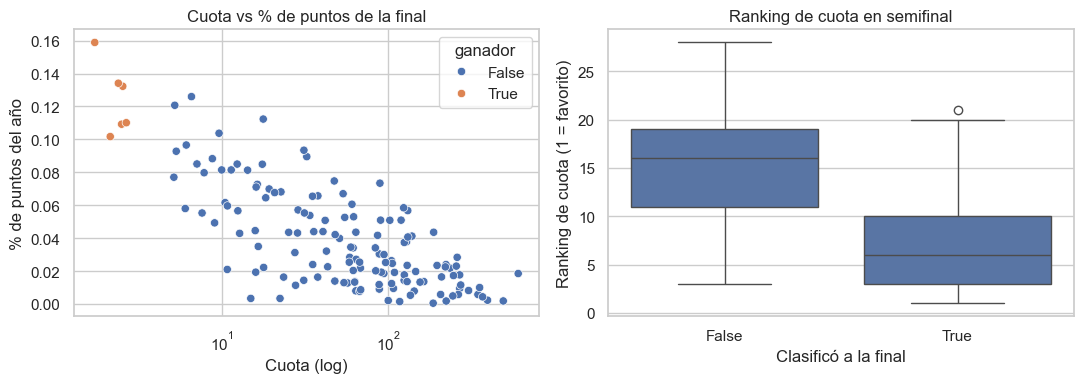

In [4]:
final['price_rank'] = final.groupby('Year')[PRICE].rank()
print(final.query('Place == 1')[['Year', 'Country', PRICE, 'price_rank']].to_string(index=False))
print('Spearman cuota vs puesto:', round(spearmanr(final[PRICE], final.Place)[0], 2))

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
sns.scatterplot(data=final, x=PRICE, y='points_share', hue=final.Place.eq(1).rename('ganador'), ax=ax[0])
ax[0].set(xscale='log', title='Cuota vs % de puntos de la final', xlabel='Cuota (log)', ylabel='% de puntos del año')
semi['price_rank'] = semi.groupby(['Year', 'stage'])[PRICE].rank()
sns.boxplot(data=semi, x='qualified', y='price_rank', ax=ax[1])
ax[1].set(title='Ranking de cuota en semifinal', xlabel='Clasificó a la final', ylabel='Ranking de cuota (1 = favorito)')
plt.tight_layout()

Ganador = favorito de las apuestas en los 6 años (cuotas entre 1.7 y 2.7). Spearman cuota-puesto: 0.70.

Izquierda: a menor cuota, mayor % de puntos; los 6 ganadores son los puntos con cuota más baja. En cuotas intermedias la dispersión es grande. Derecha: los clasificados tienen mediana de ranking de cuota cerca de 6 y los eliminados cerca de 16, con solape.

In [5]:
final['english'] = final['Song language'].str.contains('English')
for col in ['Region', 'Group/Solo', 'Home/Away Region', 'english']:
    print(final.groupby(col).agg(n=('Place', 'size'), share_medio=('points_share', 'mean'), ganadores=('Place', lambda s: (s == 1).sum())).round(3), '\n')
print(semi.groupby('Region').qualified.agg(['size', 'mean']).round(2))

                        n  share_medio  ganadores
Region                                           
Former Socialist Bloc  48        0.048          2
Former Yugoslavia      20        0.047          1
Independent            21        0.037          0
Scandinavia            22        0.043          2
Western Europe         35        0.030          1 

             n  share_medio  ganadores
Group/Solo                            
Group       47        0.035          1
Solo        99        0.044          5 

                    n  share_medio  ganadores
Home/Away Region                             
Away              118        0.043          6
Home               28        0.035          0 



           n  share_medio  ganadores
english                             
False     34        0.038          1
True     112        0.042          5 

                       size  mean
Region                           
Former Socialist Bloc    65  0.51
Former Yugoslavia        27  0.56
Independent              18  0.50
Scandinavia              22  0.64
Western Europe           41  0.22


Región, idioma, formato y local/visitante: diferencias pequeñas en % de puntos con solo 6 ganadores. En semifinales la región sí separa: Europa Occidental clasifica el 22% frente al 50-64% del resto. Es una señal de voto entre países, que se mide mejor con los votos directamente.

## 4. Preprocesamiento

**Afinidad de voto.** Para cada par votante-concursante: puntos medios que el votante le dio en años anteriores, menos los puntos medios que ese concursante recibe de cualquier votante. Mide el "extra" que un país recibe de otro por encima de su nivel general, no la calidad de sus canciones.

Para cada fila, `affinity` = media de ese extra sobre los países que votan en ese concurso. Solo se usan votos de años anteriores al de la fila (para 2004, finales 1998-2003), así que no entra información del resultado que se predice. Pares sin historia cuentan como 0.

In [6]:
def votes_long(df):
    return (df.melt(id_vars=['Year', 'stage', 'Country'], value_vars=VOTERS, var_name='voter', value_name='points')
              .dropna(subset=['points']).rename(columns={'Country': 'competitor'}))

def pair_bias(votes, year):
    """Puntos medios votante->concursante menos puntos medios que recibe el concursante, con votos anteriores a `year`."""
    hist = votes[votes.Year < year]
    pair_mean = hist.groupby(['voter', 'competitor']).points.mean()
    received_mean = hist.groupby('competitor').points.mean()
    return pair_mean - received_mean.reindex(pair_mean.index.get_level_values('competitor')).values

def add_affinity(contests, bias_by_year):
    """contests: una fila por (Year, stage, competitor, voter). Devuelve la afinidad media por concursante y concurso."""
    keys = list(zip(contests.voter, contests.competitor))
    contests = contests.assign(bias=[bias_by_year[y].get(k, 0.0) for y, k in zip(contests.Year, keys)])
    return contests.groupby(['Year', 'stage', 'competitor']).bias.mean().rename('affinity').reset_index()

votes = pd.concat([votes_long(final_raw), votes_long(semi_raw)])
bias_by_year = {y: pair_bias(votes, y) for y in range(2004, 2011)}

hist_affinity = add_affinity(votes[votes.Year >= 2004], bias_by_year)
final = final.merge(hist_affinity, left_on=['Year', 'stage', 'Country'], right_on=['Year', 'stage', 'competitor'], how='left').drop(columns='competitor')
semi = semi.merge(hist_affinity, left_on=['Year', 'stage', 'Country'], right_on=['Year', 'stage', 'competitor'], how='left').drop(columns='competitor')
print('Nulos de afinidad:', final.affinity.isna().sum(), semi.affinity.isna().sum())
print(bias_by_year[2010].sort_values(ascending=False).head(8).round(1))

Nulos de afinidad: 0 0
voter      competitor
Georgia    Belgium       10.4
Spain      Andorra       10.0
Greece     Cyprus         9.9
Macedonia  Albania        8.9
Romania    Moldova        8.9
Serbia     Macedonia      8.8
Moldova    Romania        8.6
Andorra    Spain          8.6
Name: points, dtype: float64


Los pares con más afinidad son los esperables (Grecia-Chipre, Rumanía-Moldavia, España-Andorra). Georgia-Bélgica aparece arriba con muy pocas observaciones: los pares con poca historia son ruidosos.

Spearman afinidad vs % puntos (final): 0.18
Spearman afinidad vs cuota (final): -0.14
AUC afinidad para clasificar (semifinal): 0.45


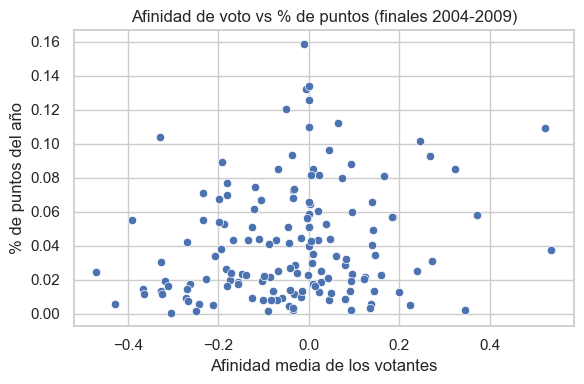

In [7]:
print('Spearman afinidad vs % puntos (final):', round(spearmanr(final.affinity, final.points_share)[0], 2))
print('Spearman afinidad vs cuota (final):', round(spearmanr(final.affinity, final[PRICE])[0], 2))
print('AUC afinidad para clasificar (semifinal):', round(roc_auc_score(semi.qualified, semi.affinity), 2))

fig, ax = plt.subplots(figsize=(6, 4))
sns.scatterplot(data=final, x='affinity', y='points_share', ax=ax)
ax.set(title='Afinidad de voto vs % de puntos (finales 2004-2009)', xlabel='Afinidad media de los votantes', ylabel='% de puntos del año')
plt.tight_layout()

La afinidad casi no se relaciona con el resultado: Spearman 0.18 con el % de puntos y AUC 0.45 para clasificar (por debajo de azar). El gráfico es una nube sin tendencia. Promediada sobre ~40 votantes, la afinidad de cada país queda cerca de 0: los votos de vecinos existen, pero pesan poco frente al total de puntos.

In [8]:
def add_features(df, group_cols):
    df = df.copy()
    df['log_price'] = np.log(df[PRICE])
    df['english'] = df['Song language'].str.contains('English').astype(int)
    df['price_rank_pct'] = df.groupby(group_cols)[PRICE].rank(pct=True)
    return df

def make_pipeline(model, num_cols, cat_cols):
    prep = ColumnTransformer([
        ('num', StandardScaler(), num_cols),
        ('cat', OneHotEncoder(handle_unknown='ignore'), cat_cols),
    ])
    return Pipeline([('prep', prep), ('model', model)])

semi = add_features(semi, ['Year', 'stage'])
final = add_features(final, ['Year'])

SEMI_CAT = ['Region', 'Home/Away Region']
FINAL_CAT = ['Region', 'Home/Away Region', 'Home/Away Country', 'Group/Solo', 'Artist gender']
# (numéricas semifinal, numéricas final, usa categóricas)
CONFIGS = {
    'sin cuota':            (['affinity', 'english'], ['affinity', 'english'], True),
    'cuota + categóricas':  (['log_price', 'price_rank_pct', 'english'], ['log_price', 'english'], True),
    'cuota + afinidad':     (['log_price', 'price_rank_pct', 'affinity'], ['log_price', 'affinity'], False),
    'cuota + afinidad + categóricas': (['log_price', 'price_rank_pct', 'affinity', 'english'], ['log_price', 'affinity', 'english'], True),
}

def build_models(config):
    semi_num, final_num, use_cat = CONFIGS[config]
    return (make_pipeline(LogisticRegression(max_iter=1000), semi_num, SEMI_CAT if use_cat else []),
            make_pipeline(Ridge(alpha=1.0), final_num, FINAL_CAT if use_cat else []))

semi_dev, semi_test = semi.query('Year < 2009').copy(), semi.query('Year == 2009').copy()
final_dev, final_test = final.query('Year < 2009').copy(), final.query('Year == 2009').copy()
print(len(semi_dev), len(semi_test), len(final_dev), len(final_test))

136 37 121 25


`log_price`: log por la cola larga de la cuota. `price_rank_pct`: ranking de cuota dentro de la semifinal, en percentil (clasifican los 10 mejores de cada grupo). Escalado y one-hot dentro de un `Pipeline`, ajustados solo con los años de entrenamiento de cada fold.

Cuatro configuraciones para separar qué aporta cada bloque: sin cuota, cuota + categóricas (región, idioma, formato), cuota + afinidad, y todo junto. El baseline es el mercado: ordenar por cuota.

## 5. Modelado

Modelos lineales, simples e interpretables para ~150 filas: regresión logística para clasificar en semifinal y Ridge sobre `points_share` en la final (la penalización estabiliza categorías con pocos casos). Ridge en vez de clasificar "ganó sí/no" porque usa los 146 finalistas y no solo 6 ganadores.

In [9]:
def semi_hits(df, score):
    """Clasificados reales entre los N con mejor score, por semifinal (N = clasificados reales)."""
    return df.groupby(['Year', 'stage']).apply(lambda g: g.nlargest(g.qualified.sum(), score).qualified.sum(), include_groups=False)

def final_ranking_metrics(df, score):
    """Por año: posición predicha del ganador real y Spearman entre ranking predicho y puesto real."""
    def metrics(g):
        pred_rank = g[score].rank(ascending=False)
        return pd.Series({'rank_ganador': pred_rank[g.Place == 1].iloc[0], 'spearman': spearmanr(pred_rank, g.Place)[0]})
    return df.groupby('Year').apply(metrics, include_groups=False)

def summarize(semi_df, final_df, score_semi, score_final):
    fm = final_ranking_metrics(final_df, score_final)
    return {'semi_aciertos': semi_hits(semi_df, score_semi).sum(),
            'semi_auc': roc_auc_score(semi_df.qualified, semi_df[score_semi]),
            'final_ganador_top1': (fm.rank_ganador == 1).sum(),
            'final_rank_ganador_medio': fm.rank_ganador.mean(),
            'final_spearman_medio': fm.spearman.mean()}

cv = LeaveOneGroupOut()
semi_dev['mercado'], final_dev['mercado'] = -semi_dev[PRICE], -final_dev[PRICE]
results = {'mercado (baseline)': summarize(semi_dev, final_dev, 'mercado', 'mercado')}
for config in CONFIGS:
    semi_model, final_model = build_models(config)
    semi_dev[config] = cross_val_predict(semi_model, semi_dev, semi_dev.qualified, groups=semi_dev.Year, cv=cv, method='predict_proba')[:, 1]
    final_dev[config] = cross_val_predict(final_model, final_dev, final_dev.points_share, groups=final_dev.Year, cv=cv)
    results[config] = summarize(semi_dev, final_dev, config, config)

random_hits = semi_dev.groupby(['Year', 'stage']).qualified.agg(lambda q: q.sum() ** 2 / len(q)).sum()
print(f'CV 2004-2008 | semifinal: 60 clasificados, esperado al azar {random_hits:.1f} | final: 5 años')
pd.DataFrame(results).T.round(3)

CV 2004-2008 | semifinal: 60 clasificados, esperado al azar 27.0 | final: 5 años

,semi_aciertos,semi_auc,final_ganador_top1,final_rank_ganador_medio,final_spearman_medio
mercado (baseline),46.0,0.862,5.0,1.0,0.701
sin cuota,35.0,0.631,0.0,8.5,0.253
cuota + categóricas,48.0,0.859,4.0,1.4,0.722
cuota + afinidad,46.0,0.837,5.0,1.0,0.706
cuota + afinidad + categóricas,48.0,0.867,4.0,1.4,0.720


Sin cuota el modelo apenas supera al azar en semifinal (35 vs 27 esperados, AUC 0.63) y no acierta ningún ganador. Añadir afinidad a la cuota no cambia nada respecto al mercado (46 aciertos, ganador primero los 5 años, Spearman 0.71 vs 0.70). Cuota + categóricas mejora un poco en semifinal (48 vs 46) y en Spearman (0.72 vs 0.70), a cambio de fallar al ganador de 2006.

Los datos del festival aportan poco sobre el mercado; la mejora, si la hay, viene de la región en semifinales.

## 6. Evaluación

Modelo elegido: `cuota + categóricas`. Añadir afinidad no mejora ninguna métrica de forma apreciable, así que se queda fuera por simplicidad. Test 2009, usado una sola vez, frente al baseline.

In [10]:
CHOSEN = 'cuota + categóricas'
semi_model, final_model = build_models(CHOSEN)
semi_test['mercado'], final_test['mercado'] = -semi_test[PRICE], -final_test[PRICE]
semi_test[CHOSEN] = semi_model.fit(semi_dev, semi_dev.qualified).predict_proba(semi_test)[:, 1]
final_test[CHOSEN] = final_model.fit(final_dev, final_dev.points_share).predict(final_test)

pd.DataFrame({name: summarize(semi_test, final_test, name, name) for name in ['mercado', CHOSEN]}).T.round(3)

,semi_aciertos,semi_auc,final_ganador_top1,final_rank_ganador_medio,final_spearman_medio
mercado,15.0,0.865,1.0,1.0,0.671
cuota + categóricas,14.0,0.803,1.0,1.0,0.746


Test 2009: ambos aciertan al ganador (Noruega). El modelo ordena mejor la final (Spearman 0.75 vs 0.67) pero clasifica algo peor en semifinal (14 vs 15 aciertos, AUC 0.80 vs 0.87). Resultado mixto, consistente con la validación cruzada: no hay una mejora clara sobre el mercado.

In [11]:
errors = final_dev.assign(error=final_dev.points_share - final_dev[CHOSEN])
cols = ['Year', 'Country', PRICE, 'Place', 'points_share', CHOSEN, 'error']
print(errors.nlargest(5, 'error')[cols].round(3).to_string(index=False))
print(errors.nsmallest(5, 'error')[cols].round(3).to_string(index=False))

 Year   Country  Approximate Betting Prices  Place  points_share  cuota + categóricas  error
 2004    Turkey                      31.264      4         0.093                0.031  0.062
 2006   Finland                       2.546      1         0.132                0.081  0.051
 2008    Norway                      47.593      5         0.075                0.026  0.049
 2006    Russia                      17.804      2         0.112                0.068  0.045
 2006 Lithuania                      89.542      6         0.073                0.029  0.044
 Year        Country  Approximate Betting Prices  Place  points_share  cuota + categóricas  error
 2007         Latvia                      17.907     16         0.022                0.079 -0.057
 2004        Belgium                      14.983     22         0.003                0.059 -0.056
 2004        Ireland                      22.461     22         0.003                0.056 -0.053
 2007         Sweden                      10.820  

El modelo subestima a los ganadores (Finlandia 2006: 13% real vs 8% predicho): un modelo lineal en log-cuota no capta lo concentrado del voto en el primero. Los mayores sobrepronósticos son países con cuota media que quedaron abajo (Letonia 2007, Bélgica e Irlanda 2004).

## 7. Interpretación y predicción 2010

Modelos reentrenados con 2004-2009 completo.

In [12]:
semi_model.fit(semi, semi.qualified)
final_model.fit(final, final.points_share)

def coefficients(pipe):
    return pd.Series(pipe[-1].coef_.ravel(), index=pipe[0].get_feature_names_out()).sort_values()

print(pd.concat({'semifinal (log-odds)': coefficients(semi_model), 'final (% puntos)': coefficients(final_model)}, axis=1).round(3))

                                   semifinal (log-odds)  final (% puntos)
num__price_rank_pct                              -1.086               NaN
cat__Region_Western Europe                       -0.977            -0.007
num__log_price                                   -0.733            -0.025
cat__Region_Independent                          -0.290            -0.001
cat__Home/Away Region_Home                       -0.167            -0.002
num__english                                     -0.135            -0.001
cat__Region_Scandinavia                          -0.118            -0.006
cat__Home/Away Region_Away                        0.167             0.002
cat__Region_Former Socialist Bloc                 0.524             0.008
cat__Region_Former Yugoslavia                     0.862             0.007
cat__Artist gender_Both                             NaN            -0.004
cat__Home/Away Country_Away                         NaN            -0.002
cat__Group/Solo_Group                 

Semifinal: tras la cuota, la región es lo que más pesa (Europa Occidental -0.98 en log-odds, Ex-Yugoslavia +0.86, Bloque ex-socialista +0.52). Final: la cuota domina (-0.025 de % de puntos por desviación estándar de `log_price`); el resto de coeficientes está entre 0.001 y 0.008.

In [13]:
SEMI_2010 = {
    'SF1': ['Moldova', 'Russia', 'Estonia', 'Slovakia', 'Finland', 'Latvia', 'Serbia', 'Bosnia and Herzegovina', 'Poland',
            'Belgium', 'Malta', 'Albania', 'Greece', 'Portugal', 'Macedonia', 'Belarus', 'Iceland'],
    'SF2': ['Lithuania', 'Armenia', 'Israel', 'Denmark', 'Switzerland', 'Sweden', 'Azerbaijan', 'Ukraine', 'Netherlands',
            'Romania', 'Slovenia', 'Ireland', 'Bulgaria', 'Cyprus', 'Croatia', 'Georgia', 'Turkey'],
}
SEMI_EXTRA_VOTERS = {'SF1': ['France', 'Germany', 'Spain'], 'SF2': ['Norway', 'United Kingdom']}
all_2010 = test_2010.Country.tolist()

def contests_2010():
    """Una fila por (stage, concursante, votante) según las reglas de voto de 2010."""
    rows = [('F', c, v) for c in all_2010 for v in all_2010 if v != c]
    for sf, countries in SEMI_2010.items():
        rows += [(sf, c, v) for c in countries for v in countries + SEMI_EXTRA_VOTERS[sf] if v != c]
    return pd.DataFrame(rows, columns=['stage', 'competitor', 'voter']).assign(Year=2010)

aff_2010 = add_affinity(contests_2010(), bias_by_year).set_index(['stage', 'competitor']).affinity
country_semi = {c: sf for sf, countries in SEMI_2010.items() for c in countries}

pred_2010 = test_2010.assign(stage=test_2010.Country.map(country_semi).fillna('directo'))
pred_2010 = add_features(pred_2010, ['stage'])
is_semi = pred_2010.stage != 'directo'

semi_rows = pred_2010[is_semi].assign(affinity=[aff_2010[(s, c)] for s, c in zip(pred_2010[is_semi].stage, pred_2010[is_semi].Country)])
pred_2010['p_qualify'] = 1.0
pred_2010.loc[is_semi, 'p_qualify'] = semi_model.predict_proba(semi_rows)[:, 1]
pred_2010['affinity'] = [aff_2010[('F', c)] for c in pred_2010.Country]
pred_2010['pred_share'] = final_model.predict(pred_2010).clip(min=0)
pred_2010['win_index'] = pred_2010.p_qualify * pred_2010.pred_share
pred_2010['win_index'] /= pred_2010.win_index.sum()
pred_2010['market_prob'] = (1 / pred_2010[PRICE]) / (1 / pred_2010[PRICE]).sum()

top10 = pred_2010.nlargest(10, 'win_index')[['Country', 'stage', PRICE, 'p_qualify', 'pred_share', 'win_index', 'market_prob']]
print(top10.round(3).to_string(index=False))

   Country   stage  Approximate Betting Prices  p_qualify  pred_share  win_index  market_prob
Azerbaijan     SF2                       3.221      0.977       0.101      0.090        0.202
   Germany directo                       3.250      1.000       0.086      0.078        0.200
    Israel     SF2                       6.567      0.935       0.084      0.071        0.099
   Croatia     SF2                      13.653      0.941       0.072      0.062        0.048
   Armenia     SF2                      13.160      0.914       0.074      0.061        0.049
    Norway directo                      14.307      1.000       0.061      0.055        0.045
  Slovakia     SF1                      38.267      0.929       0.056      0.047        0.017
    Greece     SF1                      20.000      0.835       0.054      0.041        0.032
   Denmark     SF2                      11.460      0.844       0.051      0.039        0.057
     Spain directo                      53.533      1.000   

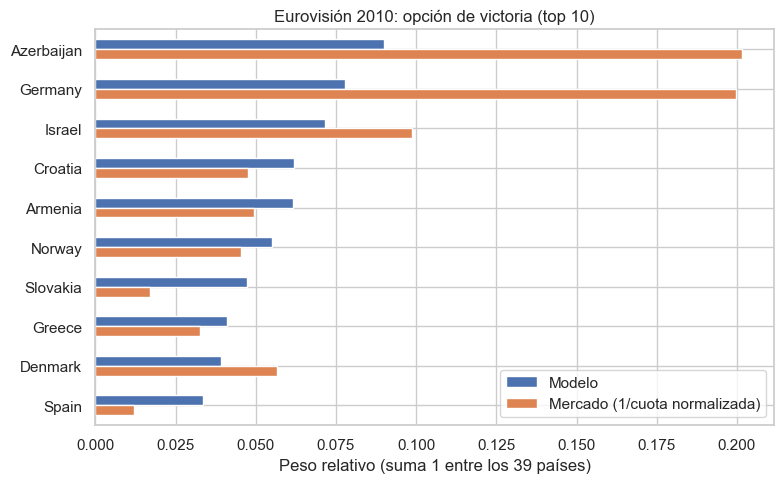

In [14]:
ax = top10.set_index('Country')[['win_index', 'market_prob']].rename(
    columns={'win_index': 'Modelo', 'market_prob': 'Mercado (1/cuota normalizada)'}).plot.barh(figsize=(8, 5))
ax.invert_yaxis()
ax.set(title='Eurovisión 2010: opción de victoria (top 10)', xlabel='Peso relativo (suma 1 entre los 39 países)', ylabel='')
plt.tight_layout()

Azerbaiyán y Alemania encabezan, igual que en el mercado; con cuotas casi iguales (3.22 y 3.25), Alemania queda debajo por el coeficiente de Europa Occidental. El modelo reparte más que el mercado y sube a países del Este con cuota media (Eslovaquia, Croacia, Armenia) por el efecto región. España aparece 10ª solo porque tiene la final asegurada. El índice sirve para ordenar, no es una probabilidad calibrada.

In [15]:
for sf in SEMI_2010:
    print(sf, pred_2010[pred_2010.stage == sf].nlargest(10, 'p_qualify').Country.tolist())

SF1 ['Slovakia', 'Belarus', 'Greece', 'Serbia', 'Albania', 'Belgium', 'Moldova', 'Bosnia and Herzegovina', 'Russia', 'Iceland']
SF2 ['Azerbaijan', 'Croatia', 'Israel', 'Armenia', 'Denmark', 'Sweden', 'Turkey', 'Ukraine', 'Romania', 'Ireland']


## 8. Conclusiones, limitaciones y próximos pasos

El mercado de apuestas es el mejor predictor disponible: el favorito ganó los 6 años y ningún modelo construido con los datos del festival lo supera de forma clara. Sin cuota, las variables del dataset apenas predicen; la afinidad de voto entre países, medida con el histórico de votos, no aporta información que el mercado no tenga. El único matiz útil es la región en semifinales.

Recomendación: usar las cuotas como predicción principal. Para 2010 los candidatos son Azerbaiyán y Alemania, prácticamente empatados en mercado y modelo; a diferencia de 2004-2009 no hay un favorito claro (cuota 3.2 frente a 1.7-2.7 de ganadores anteriores).

Limitaciones:
- 6 años y 6 ganadores: los efectos distintos de la cuota tienen mucha incertidumbre.
- Las cuotas históricas son un promedio de Betfair de periodo no especificado. Si incluye apuestas durante el festival, contienen parte del resultado y el rendimiento histórico está sobreestimado. Es la limitación principal, dado que sin cuota el modelo casi no predice.
- En 2010 las semifinales pasan a 50% jurado / 50% televoto; el histórico es casi todo televoto.
- La afinidad de pares con poca historia es ruidosa; no se aplicó ningún mínimo de observaciones.
- El índice de victoria no es una probabilidad calibrada.

Próximos pasos: probar la afinidad sobre el reparto de votos (predecir cuántos puntos da cada país a cada concursante) en lugar de agregarla por concursante, y actualizar las cuotas justo antes de la final.